In [4]:
# Load cleaned dataset from Step 3 for EDA
import pandas as pd

# for all charts
import matplotlib.pyplot as plt

## for formatting axis labels as £
import matplotlib.ticker as mtick

# Load cleaned dataset from processed folder
df = pd.read_csv("../data/processed/cleaned_data.csv", parse_dates=['InvoiceDate'])
## parse_dates converts InvoiceDate from string to datetime

print("Shape:", df.shape)
df.head()

Shape: (779425, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [8]:
# # Extract time components from InvoiceDate for use in trend analysis below
df['Year'] =  df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df['MonthName'] =  df['InvoiceDate'].dt.month_name()
df['Hour'] =  df['InvoiceDate'].dt.hour
df['Day'] =  df['InvoiceDate'].dt.day_name()

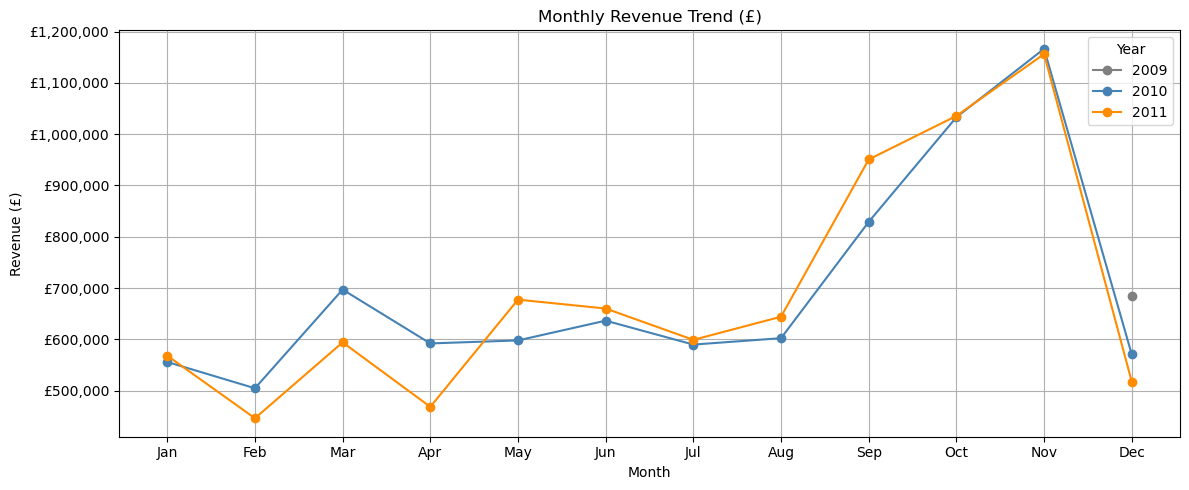

In [9]:
# Group revenue by Year and Month to see monthly totals
monthly_rev =  df.groupby(['Year','Month'])['Revenue'].sum().reset_index()

# Short month labels for x-axis
month_labels =  ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

# Assign a colour to each year so lines are distinguishable
color_map = { 2009: 'gray', 2010: 'steelblue', 2011: 'darkorange'}

fig, ax = plt.subplots(figsize=(12,5))

# Plot one line per year
for year in monthly_rev['Year'].unique():
    subset = monthly_rev[monthly_rev['Year'] == year]
    ax.plot (subset['Month'], subset['Revenue'],marker='o',color=color_map.get(year, 'black'),label=year)

ax.set_title ("Monthly Revenue Trend (£)")
ax.set_xlabel("Month")
ax.set_ylabel ("Revenue (£)")

ax.set_xticks(range(1,13))

# replace numbers with month names
ax.set_xticklabels (month_labels)


ax.grid(True)

## format y-axis as £
ax.yaxis.set_major_formatter (mtick.StrMethodFormatter('£{x:,.0f}'))

ax.legend(title="Year")

plt.tight_layout()
plt.show()

#Note:2009 data only contains December. The full yearly trends are visible for 2010 and 2011.

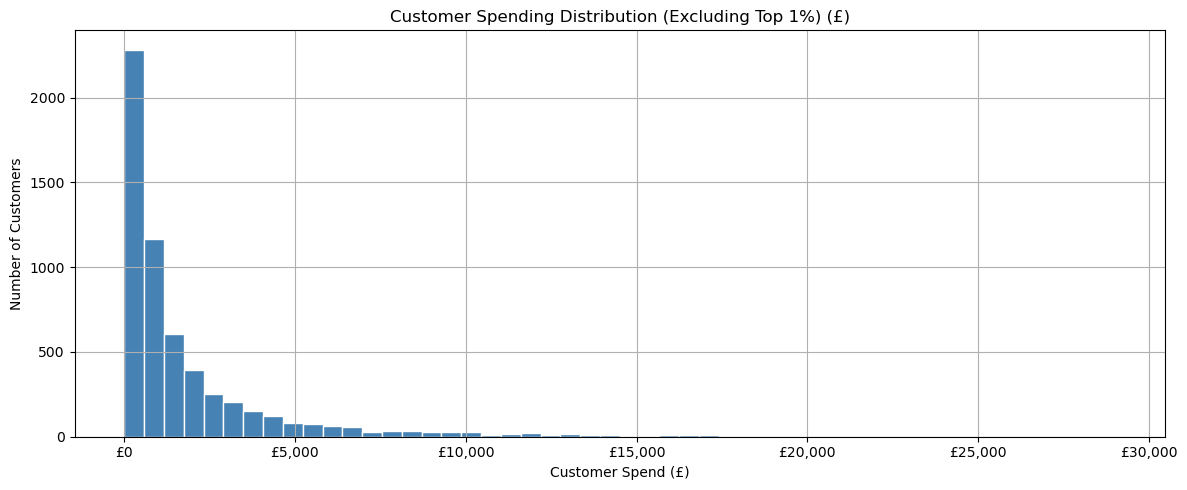

In [10]:
# Sum total revenue per customer
customer_rev =  df.groupby('Customer ID')['Revenue'].sum()

fig, ax = plt.subplots(figsize=(12,5))

# Remove top 1% of spenders to prevent extreme outliers skewing the chart
filtered =  customer_rev[customer_rev < customer_rev.quantile(0.99)]

ax.hist(filtered, bins=50, color='steelblue', edgecolor='white')

ax.set_title ("Customer Spending Distribution (Excluding Top 1%) (£)")

ax.set_xlabel("Customer Spend (£)")
ax.set_ylabel("Number of Customers")
ax.grid(True)

# format x-axis as £
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))

plt.tight_layout()
plt.show()

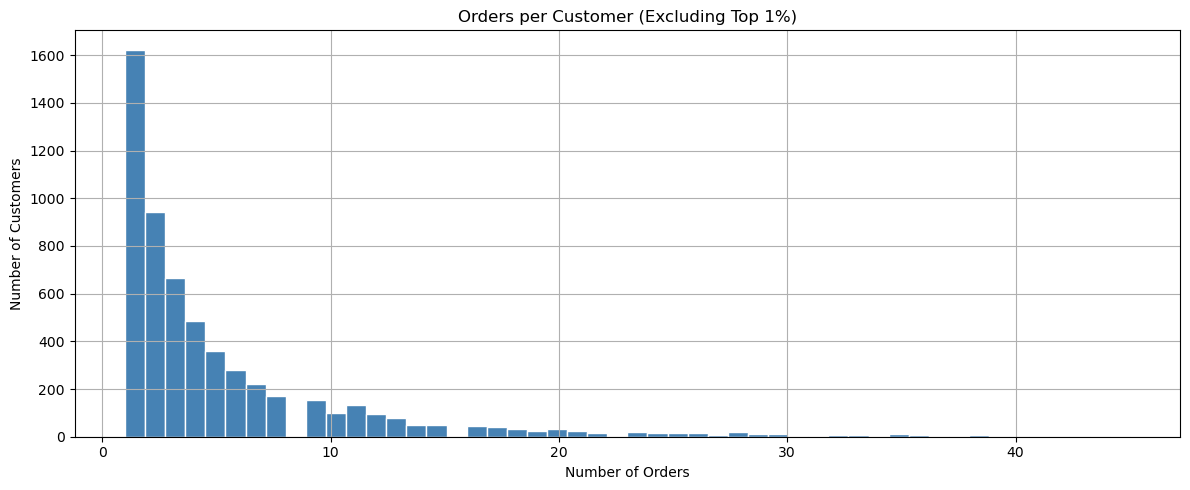

Customers with only 1 order: 1623


In [11]:
# Count unique invoices per customer. each invoice = one order
orders_per_customer = df.groupby('Customer ID')['Invoice'].nunique()

fig, ax = plt.subplots(figsize=(12,5))

#  Remove top 1% to avoid chart being distorted by very high frequency buyers
filtered =  orders_per_customer[orders_per_customer < orders_per_customer.quantile(0.99)]

ax.hist(filtered, bins=50, color='steelblue', edgecolor='white')

ax.set_title("Orders per Customer (Excluding Top 1%)")
ax.set_xlabel("Number of Orders")
ax.set_ylabel("Number of Customers")
ax.grid(True)

plt.tight_layout()
plt.show()

# Count customers who ordered exactly once 
print("Customers with only 1 order:", (orders_per_customer == 1).sum())

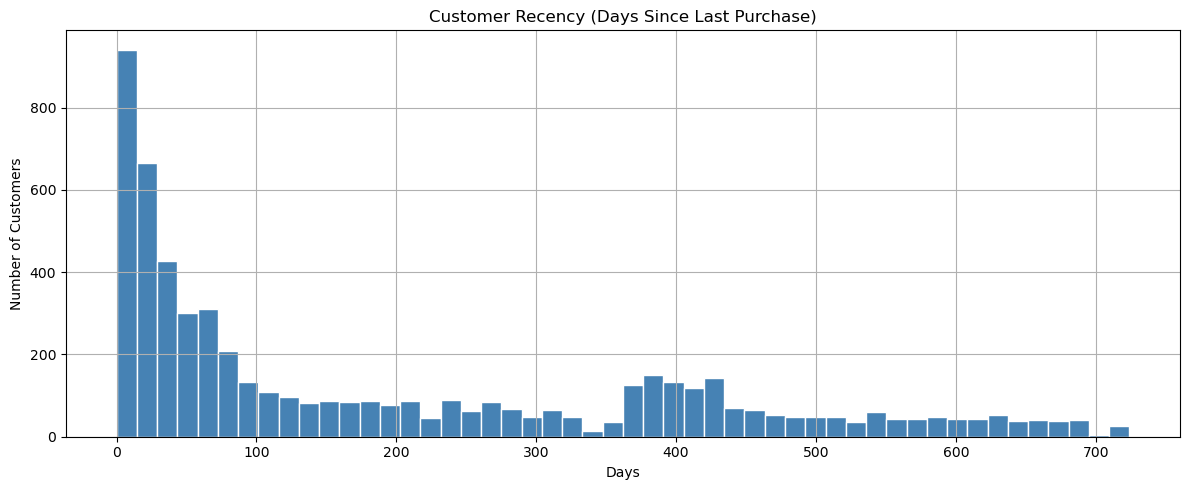

Recency statistics:
count    5878.000000
mean      200.331916
std       209.338707
min         0.000000
25%        25.000000
50%        95.000000
75%       379.000000
max       738.000000
Name: InvoiceDate, dtype: float64

Customers inactive at different thresholds:
  30 days: 4,230 customers (71.96%)
  60 days: 3,482 customers (59.24%)
  90 days: 2,989 customers (50.85%)
  120 days: 2,757 customers (46.9%)
  180 days: 2,400 customers (40.83%)
  270 days: 1,926 customers (32.77%)
  365 days: 1,609 customers (27.37%)


In [12]:
# # Use the latest date in the dataset as the reference point for recency
snapshot_date = df['InvoiceDate'].max()

# Get each customer's most recent purchase date
recency = df.groupby('Customer ID')['InvoiceDate'].max()


# Calculate how many days ago each customer last purchased
recency_days =  (snapshot_date - recency).dt.days

fig, ax = plt.subplots(figsize=(12,5))


# Remove top 1% to avoid very inactive customers distorting the chart
filtered = recency_days[recency_days < recency_days.quantile(0.99)]

ax.hist(filtered, bins=50, color='steelblue', edgecolor='white')

ax.set_title ("Customer Recency (Days Since Last Purchase)")
ax.set_xlabel("Days")
ax.set_ylabel ("Number of Customers")
ax.grid(True)

plt.tight_layout()
plt.show()

print ("Recency statistics:")
# min, max, mean, std, quartiles
print(recency_days.describe())

print()

#Count how many customers have been inactive at various thresholds
print ("Customers inactive at different thresholds:")
for days in [30, 60, 90, 120, 180, 270, 365]:

     # customers inactive for at least X days
    count = (recency_days >= days).sum()

    # as percentage of all customers
    pct   = round(count / len(recency_days) * 100, 2)
    print(f"  {days} days: {count:,} customers ({pct}%)")

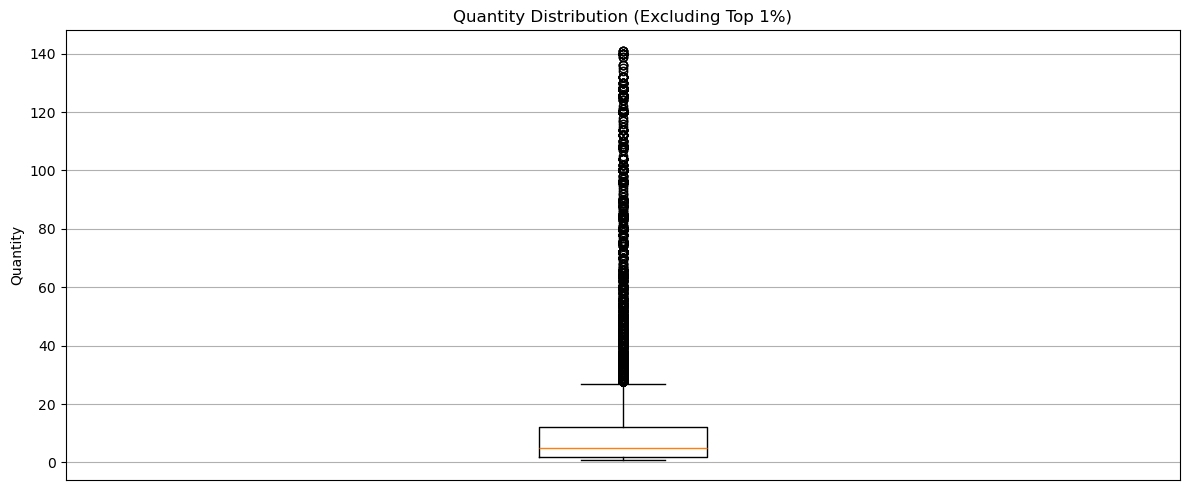

In [13]:

fig, ax = plt.subplots(figsize=(12,5))

# Remove top 1% of quantities to prevent bulk orders hiding the typical distribution
filtered = df[df['Quantity'] < df['Quantity'].quantile(0.99)]['Quantity']

# shows median, quartiles and outliers in one chart
ax.boxplot(filtered)

ax.set_title ("Quantity Distribution (Excluding Top 1%)")
ax.set_ylabel("Quantity")
ax.set_xlabel ("")

# hide x-axis ticks - only one box so no labels needed
ax.set_xticks([])

ax.grid(True)

plt.tight_layout()
plt.show()

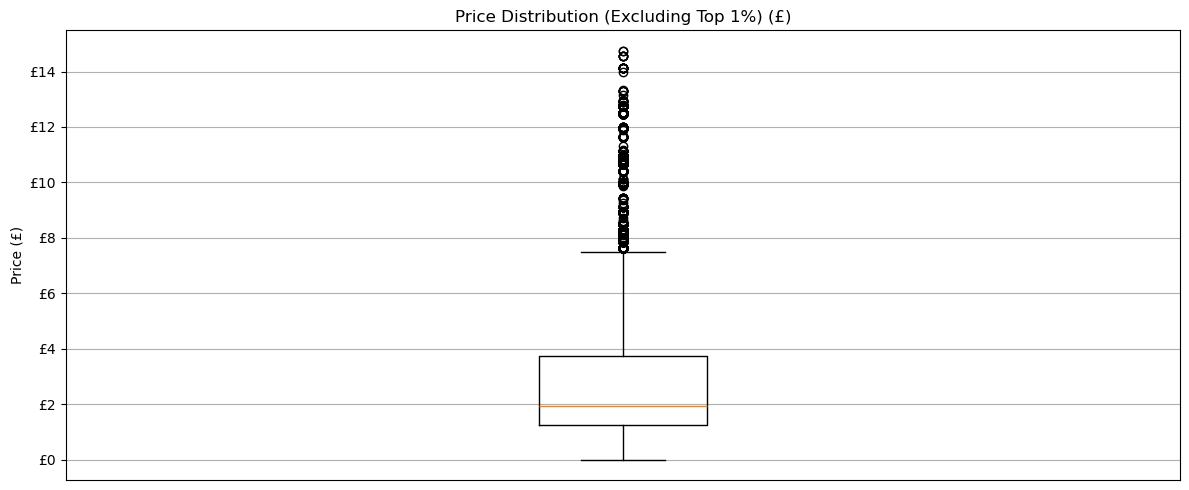

In [14]:

fig, ax = plt.subplots(figsize=(12,5))

# Remove top 1% of prices to prevent expensive items hiding the typical price range
filtered =  df[df['Price'] < df['Price'].quantile(0.99)]['Price']

 # shows median, quartiles and outliers
ax.boxplot(filtered)

ax.set_title("Price Distribution (Excluding Top 1%) (£)")
ax.set_ylabel("Price (£)")
ax.set_xlabel("")

 # hide x-axis ticks
ax.set_xticks([])

ax.grid(True)

# format y-axis as £
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))

plt.tight_layout()
plt.show()

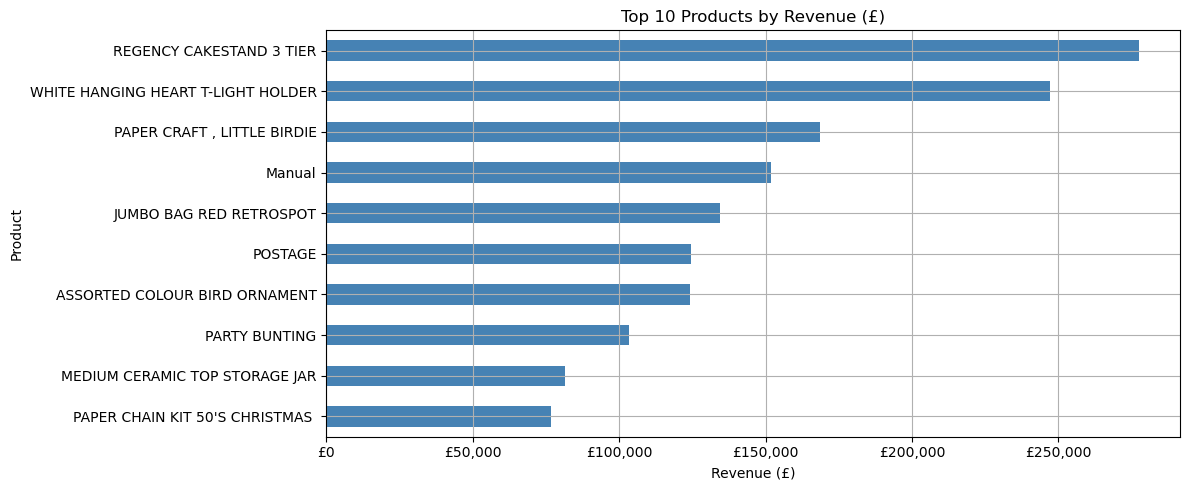

In [15]:
# Find products contributing most to revenue

# Sum revenue per product, sort ascending, take last 10 = top 10 highest earners
top_products =  df.groupby('Description')['Revenue'].sum().sort_values(ascending=True).tail(10)

fig, ax = plt.subplots(figsize=(12,5))

# horizontal bar chart
top_products.plot(kind='barh', color='steelblue', ax=ax)

ax.set_title ("Top 10 Products by Revenue (£)")
ax.set_xlabel("Revenue (£)")
ax.set_ylabel ("Product")
ax.grid(True)

ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))

plt.tight_layout()
plt.show()

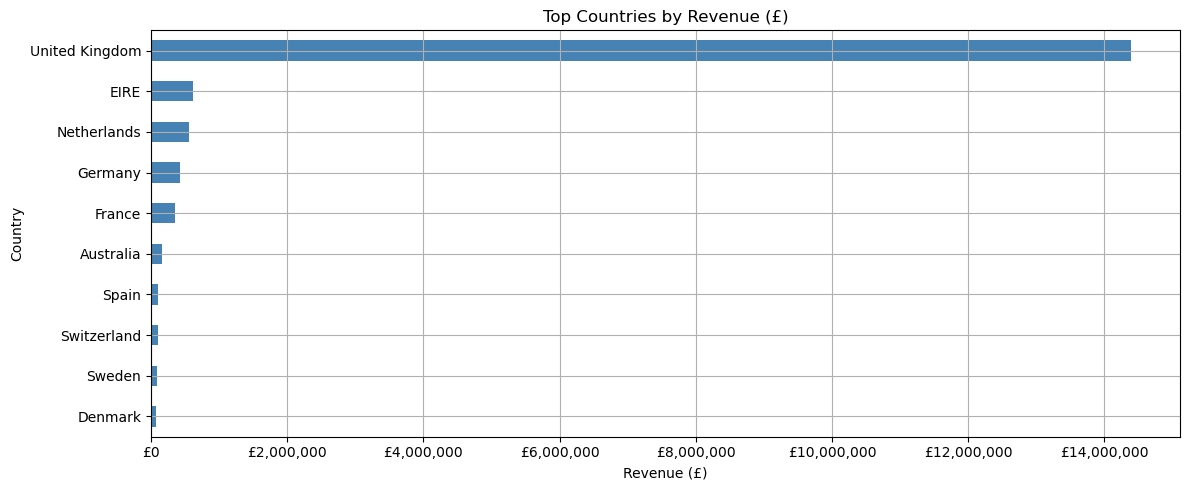

In [16]:
# Understand geographic distribution of revenue

# Sum revenue per country, sort ascending, take last 10 = top 10 by revenue
country_rev = df.groupby('Country')['Revenue'].sum().sort_values(ascending=True).tail(10)

fig, ax = plt.subplots(figsize=(12,5))

country_rev.plot(kind='barh', color='steelblue', ax=ax)

ax.set_title ("Top Countries by Revenue (£)")
ax.set_xlabel("Revenue (£)")
ax.set_ylabel("Country")

ax.grid(True)

ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))

plt.tight_layout()
plt.show()

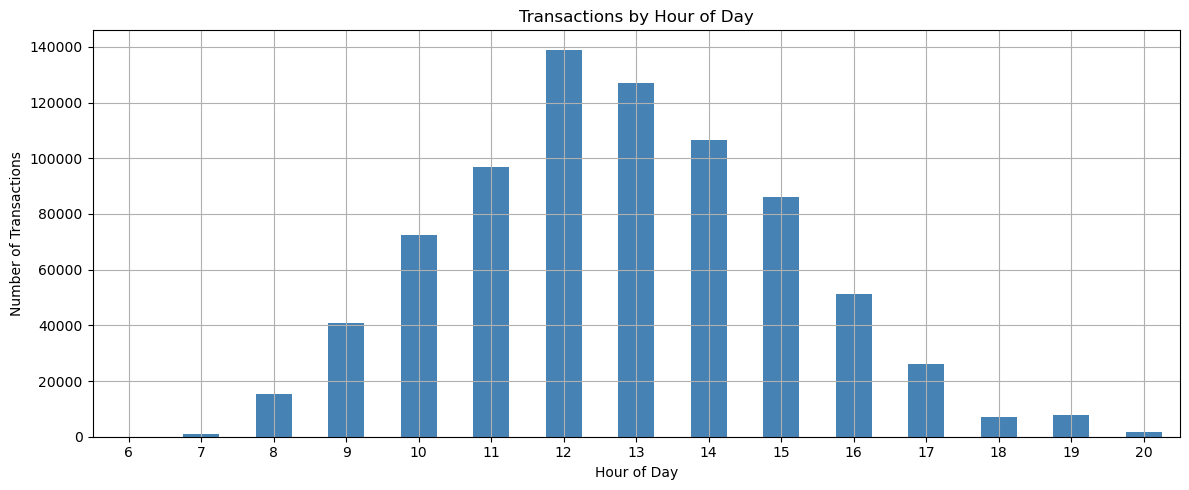

Peak hour: 12 :00


In [17]:
# Examine how transactions are distributed across hours of the day

# Count transactions per hour and sort chronologically 
hour_counts = df['Hour'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12,5))

hour_counts.plot(kind='bar', color='steelblue', ax=ax)

ax.set_title ("Transactions by Hour of Day")

ax.set_xlabel("Hour of Day")
ax.set_ylabel("Number of Transactions")

ax.grid(True)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Find the hour with the highest transaction count
print("Peak hour:", hour_counts.idxmax(), ":00")

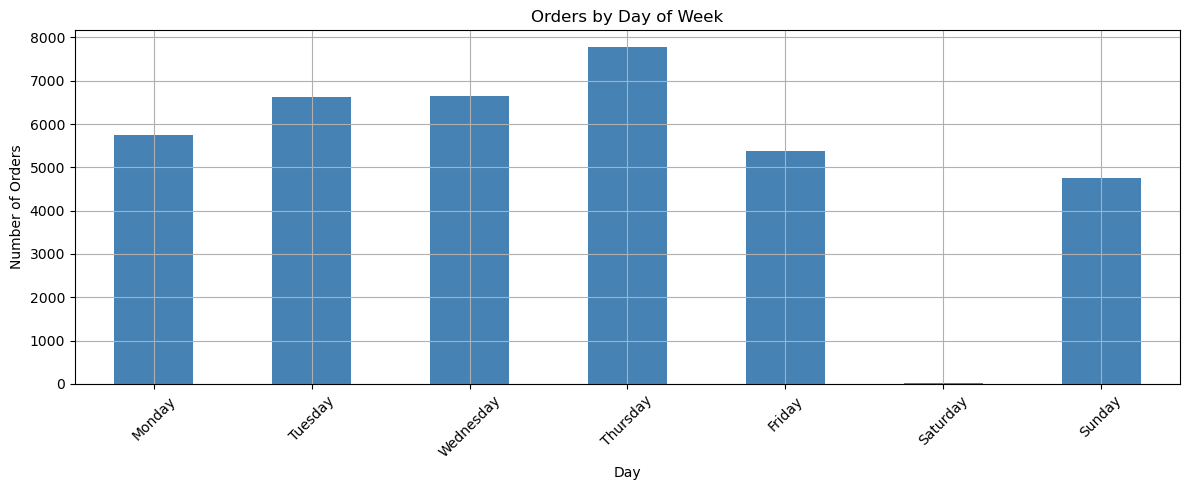

Busiest day: Thursday
Saturday orders: 30


In [19]:
# Analyse weekly purchasing behaviour

#Define correct day order - value_counts returns by frequency, not calendar order
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

# Count unique invoices per day, then reorder to match calendar week
day_counts = df.groupby('Day')['Invoice'].nunique().reindex(day_order)

fig, ax = plt.subplots(figsize=(12,5))

day_counts.plot (kind='bar', color='steelblue', ax=ax)

ax.set_title("Orders by Day of Week")
ax.set_xlabel("Day")
ax.set_ylabel("Number of Orders")
ax.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

 # day with most orders
print("Busiest day:", day_counts.idxmax())

# highlight near-zero weekend
print("Saturday orders:", day_counts['Saturday'])



In [20]:
# Compute correlation matrix between Quantity, Price and Revenue

# Values close to 1 = strong positive relationship, close to 0 = no relationship
print (df[['Quantity','Price','Revenue']].corr())

          Quantity     Price   Revenue
Quantity  1.000000 -0.004880  0.827162
Price    -0.004880  1.000000  0.135984
Revenue   0.827162  0.135984  1.000000
